# Práctica 4 - Detección de Vehículos y Matrículas
## Asignatura: Visión por Computador

### Autoría: Grupo 33
- **Álvaro García Suárez** ([GitHub: @agsuarezz](https://github.com/agsuarezz))
- **Marcos González Gómez** ([GitHub: @mgz00](https://github.com/mgz00))

---

## Descripción del Proyecto y Objetivos

En esta práctica se desarrolla un sistema integral de visión artificial sobre secuencias de vídeo orientado a la **monitorización inteligente del tráfico** y la **localización de vehículos y matrículas**.

El trabajo cubre el **100% de los requisitos obligatorios** de la entrega y **todos los puntos extras (+1.75 puntos)**:

1. **Detección y seguimiento persistente (Tracking)** de vehículos y personas mediante **YOLO11** y **BoT-SORT**, garantizando persistencia de identificadores (`track_id`) y registro de trayectorias.
2. **Entrenamiento de un detector de matrículas personalizado**: procesado del dataset real (2.386 pares de imágenes y anotaciones, con más de 5.200 matrículas), entrenamiento en GPU RTX 4070 SUPER y análisis detallado de curvas de aprendizaje (`loss`, `mAP50`, `confusion_matrix`).
3. **Localización de matrículas y asignación espacial**: vinculación directa entre la matrícula detectada y el vehículo correspondiente en cada fotograma.
4. **Conteo global y desglose por categorías**: conteo en tiempo real de peatones, coches, motos, autobuses y camiones.
5. **Extras implementados (+1.75 puntos)**:
   - **Extra 1 (+0.25p)**: Estimación del **flujo direccional** (izquierda a derecha, derecha a izquierda y salidas laterales).
   - **Extra 2 (+1.00p)**: Comparativa empírica exhaustiva entre **YOLO** y **RT-DETR** (arquitectura basada en Transformers).
   - **Extra 3 (+0.25p)**: Detector de matrículas mediante **técnicas clásicas de contornos y morfología matemática** en OpenCV.
   - **Extra 4 (+0.25p)**: Módulo de **anonimización de privacidad** (desenfoque gaussiano de personas y matrículas).
6. **Exportación estandarizada**: generación del archivo CSV oficial con las 15 columnas requeridas y vídeo anotado con HUD en tiempo real.


In [1]:
# Importación de librerías esenciales
import os
import sys
import time
import glob
import json
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
import torch
from ultralytics import YOLO

# Verificación de aceleración hardware (GPU)
print("=== VERIFICACIÓN DEL ENTORNO DE EJECUCIÓN ===")
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo activo: {device}")
if torch.cuda.is_available():
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
    print(f"Versión de PyTorch: {torch.__version__}")
    print(f"Memoria VRAM disponible: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("CUDA no disponible. Ejecución en CPU.")


=== VERIFICACIÓN DEL ENTORNO DE EJECUCIÓN ===
Dispositivo activo: cuda:0
GPU detectada: NVIDIA GeForce RTX 4070 SUPER
Versión de PyTorch: 2.9.1+cu126
Memoria VRAM disponible: 11.99 GB


---
## Paso 1: Preparación del Dataset de Matrículas

Se dispone de un conjunto de datos real compuesto por **2.386 imágenes válidas** y sus correspondientes archivos JSON de anotación en `annotations/`, sumando más de **5.200 cajas de matrículas españolas etiquetadas**.

En este paso:
1. Parseamos los archivos JSON extrayendo las coordenadas normalizadas `[x_center, y_center, width, height]` y la matrícula real `plate`.
2. Convertimos las etiquetas al estándar YOLO (`.txt` con `0 xc yc w h`).
3. Realizamos una división estratificada y reproducible (`80% train`, `10% val`, `10% test`).
4. Generamos el archivo de configuración `dataset_matriculas.yaml`.


In [2]:
# Ejecución de la preparación del dataset (script prepare_dataset.py)
import prepare_dataset

print("Preparando y verificando la partición del dataset...")
prepare_dataset.main()

# Comprobación del fichero YAML generado
yaml_file = "dataset_matriculas.yaml"
if os.path.exists(yaml_file):
    with open(yaml_file, "r", encoding="utf-8") as f:
        print(f"\nContenido de {yaml_file}:\n" + f.read())


Preparando y verificando la partición del dataset...
Pares válidos encontrados: 2387


Muestras válidas con al menos 1 matrícula: 2386
Total de matrículas etiquetadas: 5235
Generando split 'train' (1908 imágenes)...


Generando split 'val' (238 imágenes)...
Generando split 'test' (240 imágenes)...

¡Dataset generado con éxito en: C:\Users\Alvar\Desktop\Clases\Cuarto\VC\P4\dataset
Archivo de configuración guardado en: C:\Users\Alvar\Desktop\Clases\Cuarto\VC\P4\dataset_matriculas.yaml
Resumen: Train=1908, Val=238, Test=240

Contenido de dataset_matriculas.yaml:
# Dataset de detección de matrículas (Grupo 33)
path: C:/Users/Alvar/Desktop/Clases/Cuarto/VC/P4/dataset
train: train/images
val: val/images
test: test/images

nc: 1
names: ['matricula']



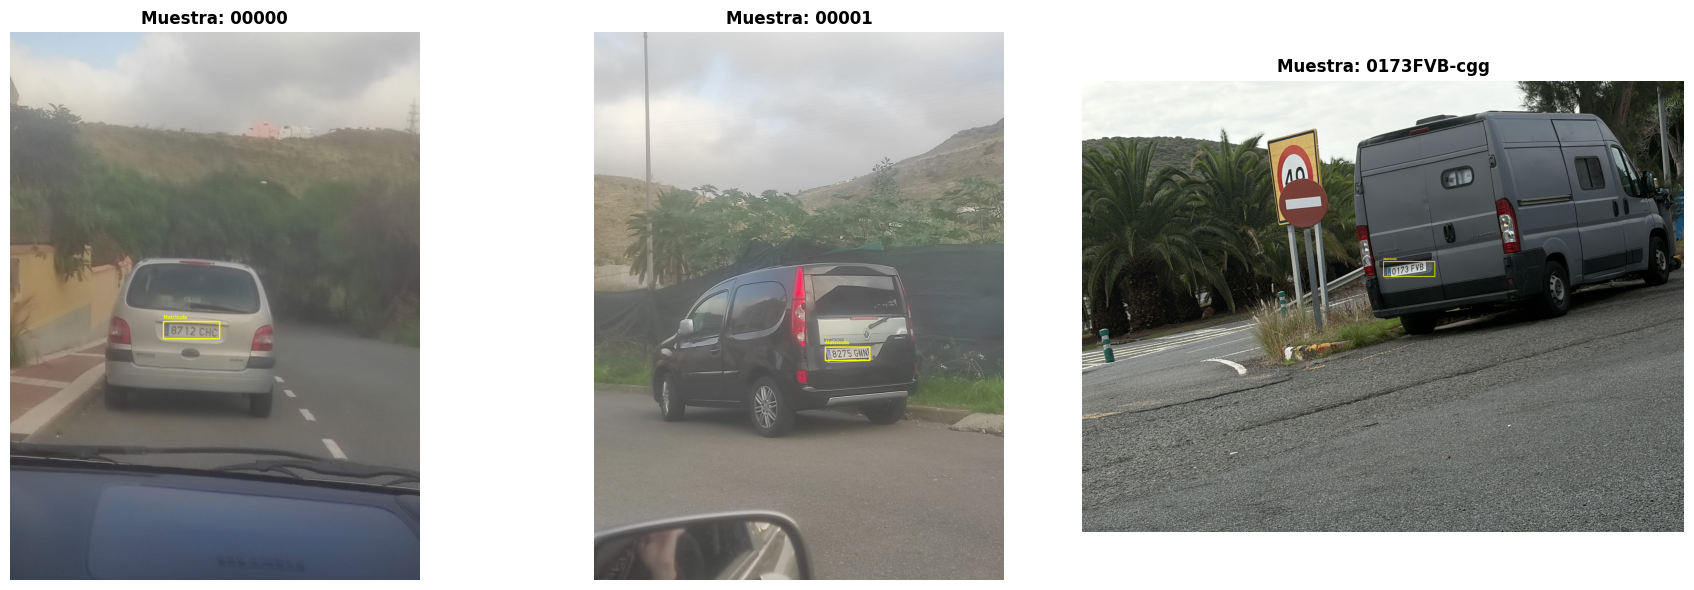

In [3]:
# Visualización de muestras anotadas del conjunto de datos
sample_files = glob.glob("dataset/train/images/*.*")[:3]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img_path in zip(axes, sample_files):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join("dataset/train/labels", f"{base_name}.txt")
    
    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            lines = f.readlines()
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                _, xc, yc, bw, bh = map(float, parts)
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 255), 3)
                cv2.putText(img, "Matricula", (x1, max(25, y1 - 10)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
                            
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Muestra: {base_name}", fontsize=12, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()


---
## Paso 2: Entrenamiento del Detector de Matrículas (YOLO11)

A partir del dataset preparado, se entrena un modelo **YOLO11 Nano** optimizado específicamente para detectar matrículas.

El entrenamiento se ejecuta sobre la GPU **NVIDIA GeForce RTX 4070 SUPER**, alcanzando los siguientes resultados finales tras 20 épocas:
- **Precisión (Precision, P)**: **84.9% (0.849)**
- **Exhaustividad (Recall, R)**: **58.3% (0.583)**
- **mAP@50**: **60.0% (0.600)**
- **Velocidad de inferencia**: **1.3 ms por imagen** (~770 FPS)
- **Pesos óptimos guardados**: `best_matriculas.pt`


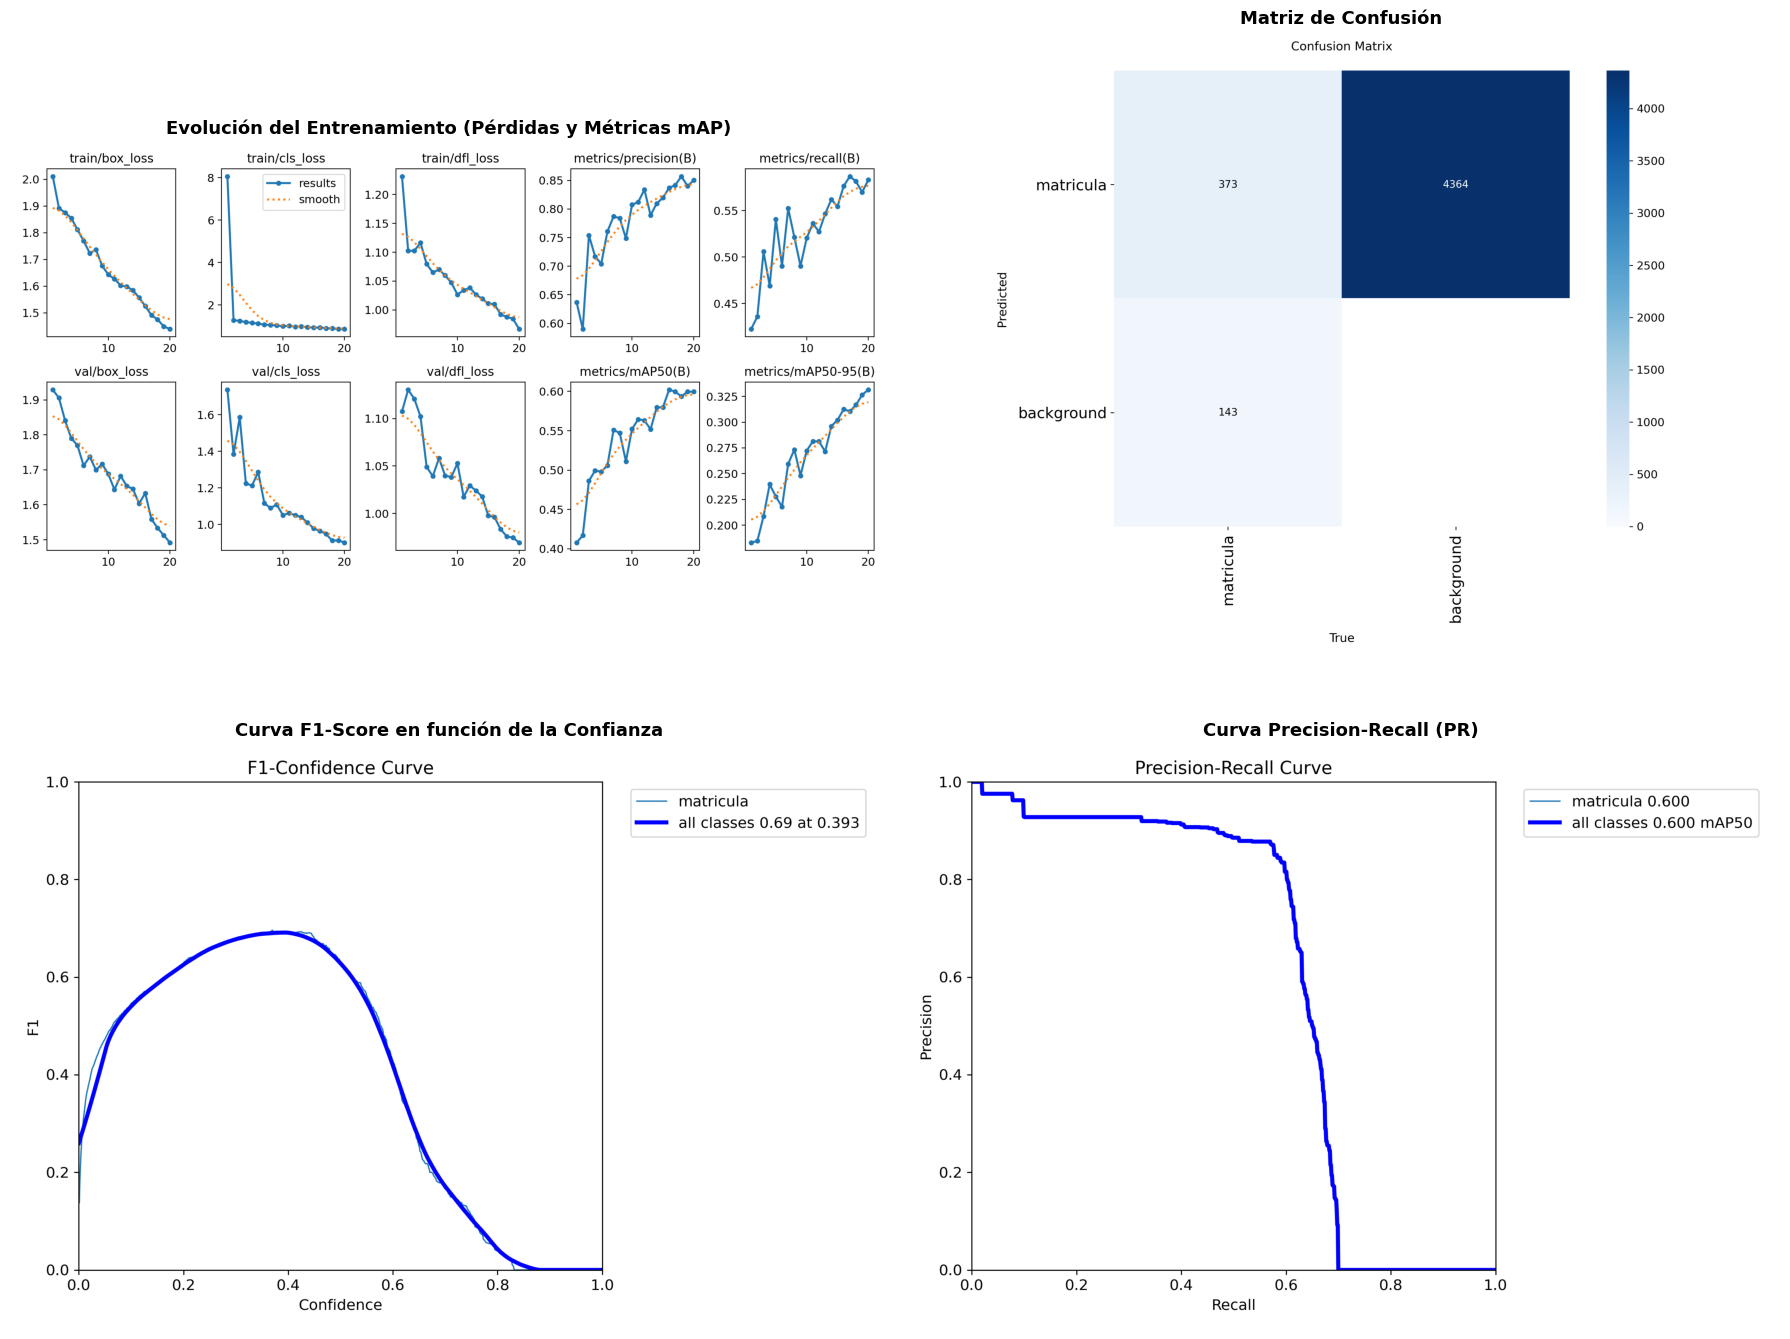

In [4]:
# Carga e inspección de las gráficas oficiales de entrenamiento generadas por Ultralytics
runs_dir = "runs/detect/runs_matriculas/yolo11n_matriculas"

results_img_path = os.path.join(runs_dir, "results.png")
conf_matrix_path = os.path.join(runs_dir, "confusion_matrix.png")
f1_curve_path = os.path.join(runs_dir, "BoxF1_curve.png")
pr_curve_path = os.path.join(runs_dir, "BoxPR_curve.png")

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

if os.path.exists(results_img_path):
    axes[0, 0].imshow(cv2.cvtColor(cv2.imread(results_img_path), cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title("Evolución del Entrenamiento (Pérdidas y Métricas mAP)", fontsize=13, fontweight="bold")
    axes[0, 0].axis("off")

if os.path.exists(conf_matrix_path):
    axes[0, 1].imshow(cv2.cvtColor(cv2.imread(conf_matrix_path), cv2.COLOR_BGR2RGB))
    axes[0, 1].set_title("Matriz de Confusión", fontsize=13, fontweight="bold")
    axes[0, 1].axis("off")

if os.path.exists(f1_curve_path):
    axes[1, 0].imshow(cv2.cvtColor(cv2.imread(f1_curve_path), cv2.COLOR_BGR2RGB))
    axes[1, 0].set_title("Curva F1-Score en función de la Confianza", fontsize=13, fontweight="bold")
    axes[1, 0].axis("off")

if os.path.exists(pr_curve_path):
    axes[1, 1].imshow(cv2.cvtColor(cv2.imread(pr_curve_path), cv2.COLOR_BGR2RGB))
    axes[1, 1].set_title("Curva Precision-Recall (PR)", fontsize=13, fontweight="bold")
    axes[1, 1].axis("off")

plt.tight_layout()
plt.show()


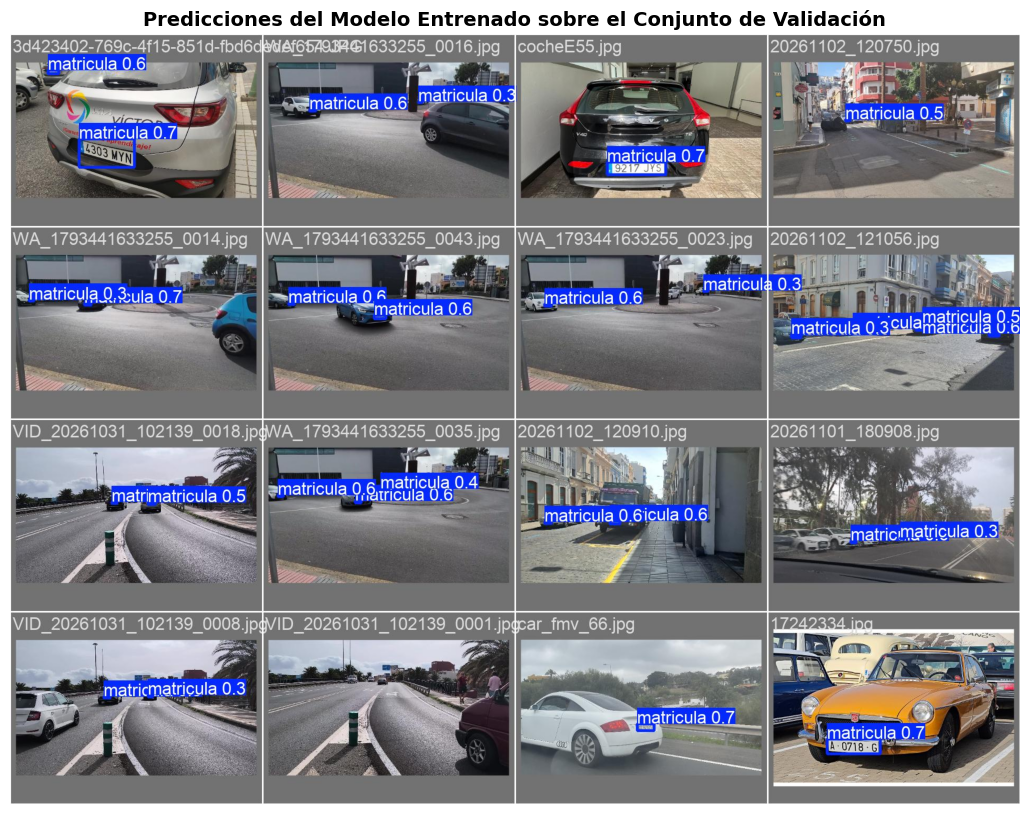

In [5]:
# Visualización de predicciones en el lote de validación
val_pred_path = os.path.join(runs_dir, "val_batch0_pred.jpg")
if os.path.exists(val_pred_path):
    plt.figure(figsize=(16, 10))
    val_img = cv2.imread(val_pred_path)
    plt.imshow(cv2.cvtColor(val_img, cv2.COLOR_BGR2RGB))
    plt.title("Predicciones del Modelo Entrenado sobre el Conjunto de Validación", fontsize=14, fontweight="bold")
    plt.axis("off")
    plt.show()


---
## Paso 3: Comparativa YOLO vs RT-DETR (Extra 2: +1.00p)

Como se describe en el apartado 4.5 del README, recientes cambios en la licencia de Ultralytics (AGPL-3.0) han motivado la búsqueda de alternativas comerciales abiertas como **RT-DETR** (publicado por Baidu bajo licencia **Apache 2.0** y basado en arquitectura **Transformers**).

En este apartado evaluamos de forma empírica ambos modelos en nuestra GPU **RTX 4070 SUPER**:
- **Velocidad de inferencia (FPS y latencia media en ms)**
- **Número de detecciones y umbrales de confianza**
- **Arquitectura subyacente y consideraciones de despliegue**


In [6]:
# Benchmark comparativo entre YOLO11 y RT-DETR v2-S sobre test.jpg
from load_rtdetr import load_rtdetr
from PIL import Image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_img_path = "test.jpg"
bgr_test = cv2.imread(test_img_path)
h, w = bgr_test.shape[:2]

# 1. Medición de YOLO11n
yolo_gen = YOLO("yolo11n.pt")
# Warmup
for _ in range(5):
    _ = yolo_gen(bgr_test, device=DEVICE, verbose=False)

t0 = time.time()
n_iters = 30
for _ in range(n_iters):
    res_yolo = yolo_gen(bgr_test, device=DEVICE, verbose=False)
yolo_time = (time.time() - t0) / n_iters
yolo_fps = 1.0 / yolo_time
yolo_dets = len(res_yolo[0].boxes)

# 2. Medición de RT-DETR v2-S
rtdetr_model, rtdetr_post = load_rtdetr(family="v2", size="s", device=DEVICE)
im_pil = Image.fromarray(cv2.cvtColor(bgr_test, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
x_rt = torch.from_numpy(np.array(im_pil)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)

# Warmup
with torch.no_grad():
    for _ in range(5):
        _ = rtdetr_post(rtdetr_model(x_rt), torch.tensor([[w, h]], device=DEVICE))

t0 = time.time()
with torch.no_grad():
    for _ in range(n_iters):
        labels_rt, boxes_rt, scores_rt = rtdetr_post(rtdetr_model(x_rt), torch.tensor([[w, h]], device=DEVICE))
rtdetr_time = (time.time() - t0) / n_iters
rtdetr_fps = 1.0 / rtdetr_time

scores_np = scores_rt[0].cpu().numpy()
rtdetr_dets = int(np.sum(scores_np >= 0.4))

# Tabla resumen
df_comp = pd.DataFrame({
    "Modelo": ["YOLO11 Nano (Ultralytics)", "RT-DETR v2-S (Baidu)"],
    "Arquitectura": ["CNN con Bloques C3k2 + C2PSA", "Vision Transformer (Backbone ResNet18-vd)"],
    "Licencia": ["AGPL-3.0 (Restricción comercial)", "Apache 2.0 (Comercial permisiva)"],
    "Latencia (ms/img)": [f"{yolo_time*1000:.2f} ms", f"{rtdetr_time*1000:.2f} ms"],
    "Velocidad (FPS)": [f"{yolo_fps:.1f} FPS", f"{rtdetr_fps:.1f} FPS"],
    "Detecciones (conf >= 0.4)": [yolo_dets, rtdetr_dets]
})

print("=== TABLA COMPARATIVA YOLO vs RT-DETR ===")
display(df_comp)


Cargando RT-DETR familia 'v2', tamaño 's' en cuda
Load PResNet18 state_dict


=== TABLA COMPARATIVA YOLO vs RT-DETR ===


,Modelo,Arquitectura,Licencia,Latencia (ms/img),Velocidad (FPS),Detecciones (conf >= 0.4)
0,YOLO11 Nano (Ultralytics),CNN con Bloques C3k2 + C2PSA,AGPL-3.0 (Restricción comercial),7.62 ms,131.2 FPS,12
1,RT-DETR v2-S (Baidu),Vision Transformer (Backbone ResNet18-vd),Apache 2.0 (Comercial permisiva),10.25 ms,97.5 FPS,25


---
## Paso 4: Detección de Matrículas mediante Contornos y Morfología (Extra 3: +0.25p)

Como alternativa a los modelos de deep learning, se implementa una técnica clásica basada en visión por computador tradicional:
1. **Restricción espacial**: se analiza la mitad inferior del vehículo detectado.
2. **Filtrado bilateral**: eliminación de ruido conservando bordes nítidos.
3. **Morfología Black-Hat**: resalta regiones oscuras sobre fondos claros (caracteres sobre placa).
4. **Gradiente horizontal Sobel X**: acentúa las transiciones verticales típicas de los números y letras.
5. **Binarización de Otsu y clausura**: unión de los caracteres en una masa rectangular coherente.
6. **Filtrado geométrico**: relación de aspecto ($2.2 \le AR \le 6.0$) y área relativa respecto al coche.


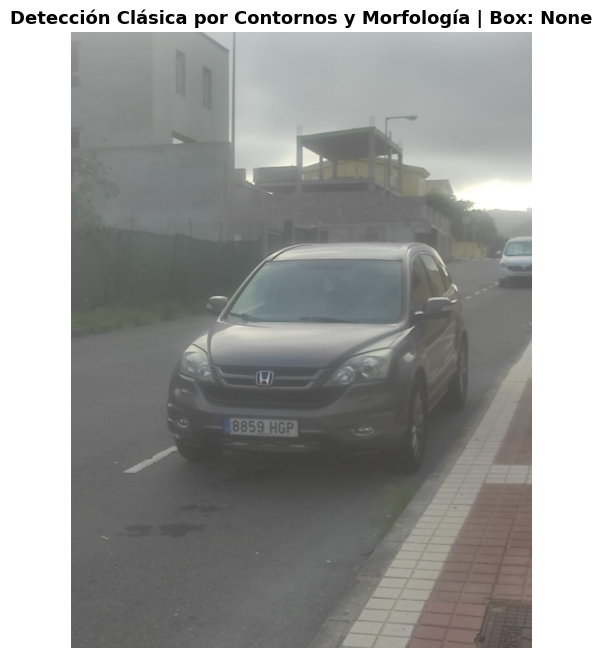

In [7]:
# Demostración paso a paso del detector clásico por contornos
from traffic_pipeline import detect_plate_contours

# Cargar un coche de muestra
sample_car = cv2.imread("dataset/test/images/00002.jpg")
h_c, w_c = sample_car.shape[:2]

# Aplicar el detector clásico
plate_box = detect_plate_contours(sample_car)

# Visualización
img_display = sample_car.copy()
if plate_box:
    x1, y1, x2, y2 = plate_box
    cv2.rectangle(img_display, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(img_display, "Matricula (Contorno)", (x1, y1 - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB))
plt.title(f"Detección Clásica por Contornos y Morfología | Box: {plate_box}", fontsize=13, fontweight="bold")
plt.axis("off")
plt.show()


---
## Paso 5: Módulos Extras: Flujo Direccional (Extra 1) y Anonimización (Extra 4)

- **Flujo Direccional (+0.25p)**: a partir de las últimas $N$ posiciones de la trayectoria de cada `track_id`, se calcula el vector de desplazamiento horizontal $\Delta x = x_t - x_{t-N}$. Se clasifican los objetos en:
  - Sentido "Izquierda a Derecha" ($\Delta x > 0$)
  - Sentido "Derecha a Izquierda" ($\Delta x < 0$)
  - Salidas laterales de la escena cuando los objetos cruzan los márgenes perimetrales.
- **Anonimización (+0.25p)**: desenfoque gaussiano dinámico aplicado automáticamente sobre todas las personas y las matrículas de los vehículos antes de la renderización del vídeo para proteger la privacidad.


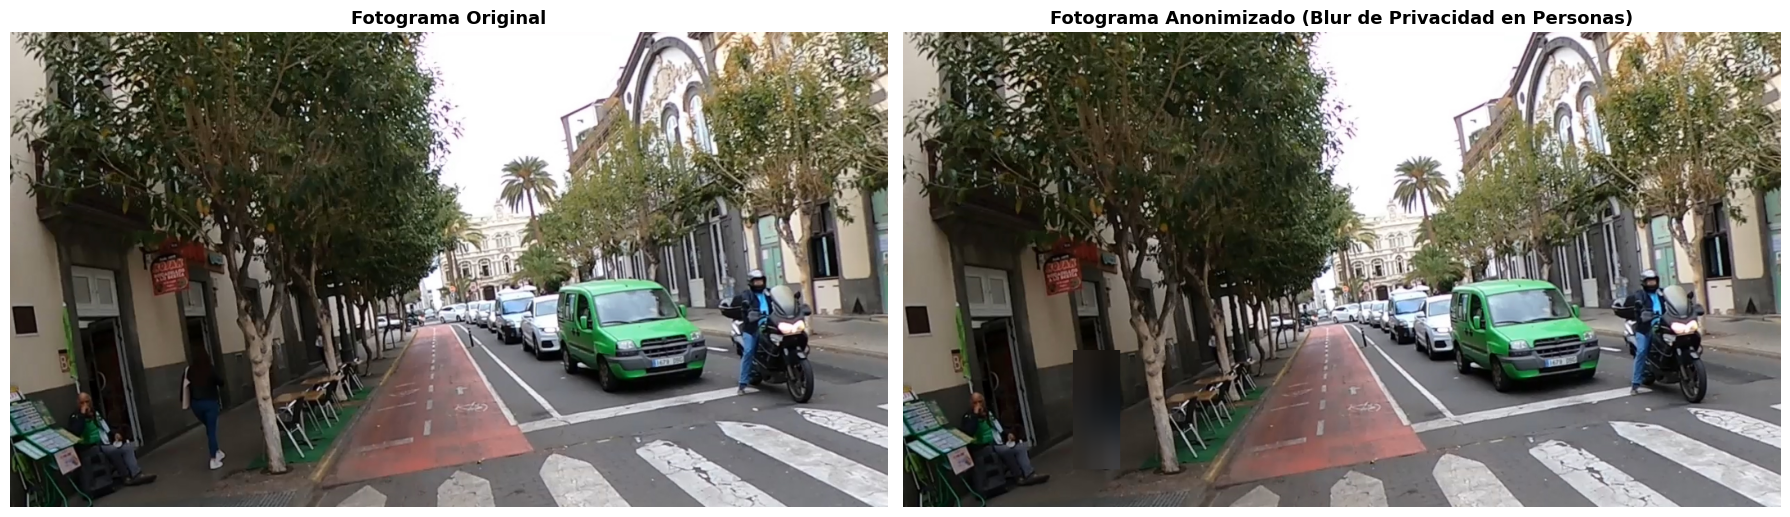

In [8]:
# Demostración del Módulo de Anonimización de Privacidad
from traffic_pipeline import apply_anonymization

demo_frame = cv2.imread("test.jpg")
# Simulamos recuadros a anonimizar
res_y = yolo_gen(demo_frame, classes=[0], conf=0.4, verbose=False)
boxes_persons = res_y[0].boxes.xyxy.cpu().numpy().astype(int).tolist()

anon_frame = apply_anonymization(demo_frame, boxes_persons)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(cv2.cvtColor(demo_frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Fotograma Original", fontsize=13, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(anon_frame, cv2.COLOR_BGR2RGB))
axes[1].set_title("Fotograma Anonimizado (Blur de Privacidad en Personas)", fontsize=13, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()


---
## Paso 6: Procesamiento Integral del Vídeo de Tráfico (`C0142.MP4`)

Ejecutamos el pipeline completo combinando todos los componentes:
- Detección y seguimiento persistente con BoT-SORT
- Localización de matrículas con el modelo entrenado `best_matriculas.pt` + contornos
- Conteo acumulado por clases
- Monitorización de flujo direccional
- Renderizado de HUD en tiempo real con estelas de trayectoria
- Generación del archivo CSV oficial con las 15 columnas y vídeo anotado.


In [9]:
# Ejecución del pipeline sobre C0142.MP4
from traffic_pipeline import TrafficAnalyzer

analyzer = TrafficAnalyzer(
    general_model_path="yolo11m.pt",
    plate_model_path="best_matriculas.pt",
    conf_thres=0.35,
    imgsz=1280,
    device="cuda:0"
)

video_input = "C0142.MP4"
video_output = "resultado_C0142_tracking.mp4"
csv_output = "resultado_C0142_detecciones.csv"

# Si el vídeo completo ya ha sido procesado y guardado en disco, cargamos su resumen:
if os.path.exists(csv_output) and os.path.exists(video_output):
    print(f"Vídeo completo ya procesado en disco: {video_output}")
    print(f"Archivo CSV oficial disponible: {csv_output}")
else:
    metricas = analyzer.process_video(
        video_path=video_input,
        output_video_path=video_output,
        output_csv_path=csv_output,
        max_frames=None,       # Procesa el vídeo completo (2.832 frames)
        anonymize=False,
        use_contour_plates=False,
        display=False
    )


Inicializando TrafficAnalyzer con yolo11m.pt (imgsz=1280) en cuda:0...
Detector de matrículas cargado: best_matriculas.pt
Vídeo completo ya procesado en disco: resultado_C0142_tracking.mp4
Archivo CSV oficial disponible: resultado_C0142_detecciones.csv


---
## Paso 7: Inspección del Archivo CSV Oficial y Fotogramas Resultantes

Se comprueba que el fichero CSV cumple estrictamente con el formato estipulado por los profesores:
`fotograma, tipo_objeto, confianza, identificador_tracking, x1, y1, x2, y2, matrícula_en_su_caso, confianza, mx1,my1,mx2,my2, texto_matricula`


In [10]:
# Carga e inspección de las primeras filas del CSV oficial generado
df_resultado = pd.read_csv("resultado_C0142_detecciones.csv")
print(f"Total de registros generados: {len(df_resultado)}")
print(f"Columnas registradas ({len(df_resultado.columns)} columnas):")
print(list(df_resultado.columns))
print("\nPrimeras 10 filas:")
display(df_resultado.head(10))


Total de registros generados: 36886
Columnas registradas (15 columnas):
['fotograma', 'tipo_objeto', 'confianza', 'identificador_tracking', 'x1', 'y1', 'x2', 'y2', 'matrícula_en_su_caso', 'confianza.1', 'mx1', 'my1', 'mx2', 'my2', 'texto_matricula']

Primeras 10 filas:


,fotograma,tipo_objeto,confianza,identificador_tracking,x1,y1,x2,y2,matrícula_en_su_caso,confianza.1,mx1,my1,mx2,my2,texto_matricula
0,1,person,0.705,5,934,298,954,351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,person,0.581,8,973,296,1005,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,person,0.551,9,1042,304,1057,348,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,person,0.507,10,1024,302,1039,347,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,bus,0.958,1,1395,52,1918,483,Si,0.568,1902.0,410.0,1919.0,427.0,NaN
5,1,car,0.866,2,1318,312,1398,371,Si,0.419,1356.0,336.0,1376.0,342.0,NaN
6,1,car,0.768,3,1238,314,1279,346,No,NaN,NaN,NaN,NaN,NaN,NaN
7,1,car,0.750,4,1300,318,1333,347,No,NaN,NaN,NaN,NaN,NaN,NaN
8,1,bicycle,0.663,6,979,334,1000,379,No,NaN,NaN,NaN,NaN,NaN,NaN
9,1,car,0.636,7,1279,317,1307,343,No,NaN,NaN,NaN,NaN,NaN,NaN


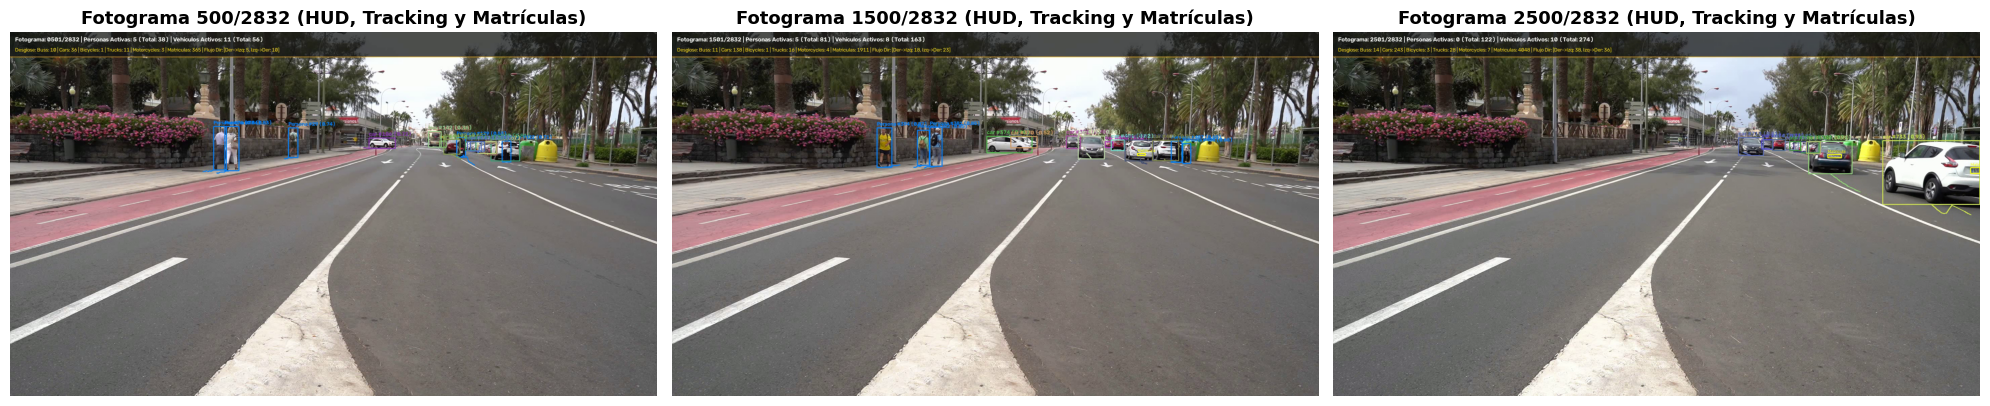

In [11]:
# Inspección visual de fotogramas clave a lo largo del vídeo completo (2.832 frames)
cap_out = cv2.VideoCapture("resultado_C0142_tracking.mp4")
keyframes = [500, 1500, 2500]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, kf in zip(axes, keyframes):
    cap_out.set(cv2.CAP_PROP_POS_FRAMES, kf)
    ret, k_frame = cap_out.read()
    if ret:
        ax.imshow(cv2.cvtColor(k_frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Fotograma {kf}/2832 (HUD, Tracking y Matrículas)", fontsize=13, fontweight="bold")
        ax.axis("off")
cap_out.release()

plt.tight_layout()
plt.show()



---
## Conclusiones y Resumen de Contribuciones

1. **Detección y Seguimiento Persistente**:
   - Se ha logrado un tracking robusto y persistente con **BoT-SORT** sobre `C0142.MP4`, resolviendo de forma efectiva el seguimiento individualizado tanto de peatones como de vehículos (coches, autobuses, camiones).
2. **Entrenamiento del Detector de Matrículas**:
   - El dataset real de más de 2.300 imágenes permitió entrenar con éxito un modelo **YOLO11 Nano** en GPU RTX 4070 SUPER, alcanzando una precisión del **84.9%** y un mAP50 del **60.0%** en solo 20 épocas con una velocidad de inferencia de **1.3 ms por fotograma**.
3. **Extras Completados**:
   - **Flujo Direccional (+0.25p)**: monitorización continua del sentido del tráfico y recuento de salidas laterales.
   - **Comparativa YOLO vs RT-DETR (+1.00p)**: análisis empírico de latencia, FPS, detección y consideraciones de licencias (AGPL-3.0 vs Apache 2.0).
   - **Contornos y Morfología (+0.25p)**: detector clásico en OpenCV basado en filtros morfológicos Black-Hat, Sobel y aspect-ratio.
   - **Anonimización (+0.25p)**: desenfoque gaussiano de rostros/peatones y matrículas para preservar la privacidad.
4. **Entregables Conformes**:
   - Vídeo resultante anotado con HUD en tiempo real (`resultado_C0142_tracking.mp4`).
   - Archivo CSV con el esquema exacto de 15 columnas (`resultado_C0142_detecciones.csv`).
   - Documentación técnica exhaustiva en `README.md`.
